# Supplementary Figure S9e. Initiating-recipient pair enrichment split by *trans*-eGene and *trans*-eProgram

For the 1,301 strictly distinct *cis*-*trans* loci, the observed count of loci with *cis* cell type *i* and method-specific *trans* cell type *j* (raw counts; no normalization) is compared with a null from 1,000 shuffles (seed 42) in which cell-type labels are permuted independently within the *cis*, *trans*-eGene and *trans*-eProgram membership rows of all 164,160 CoS. The shuffle keeps each locus's number of labels per side and method (phenotype multiplicity), the overall representation of each cell type and bulk support fixed; the combined recipient set and disjointness are recomputed after every shuffle. Tiles show enrichment = observed / null mean. Two-sided empirical P = min(1, 2 min(P_upper, P_lower)), each (1 + n)/(1 + 1,000), BH-adjusted separately within each method across the 30 off-diagonal pairs; * FDR < 0.05, ** FDR < 0.01 (the smallest attainable two-sided P is 0.002, so the smallest attainable FDR here is 0.0075 and *** cannot occur). Colour scale is linear and symmetric around 1, squished at the limits. `bound_low`/`bound_high` (observed / null 97.5% and 2.5% quantiles) are kept in the data but not drawn.

Input: `data/Figure_S9e_pair_enrichment_by_method.rds`

In [1]:
library(ggplot2)
library(scales)
res <- readRDS("data/Figure_S9e_pair_enrichment_by_method.rds")
head(res[!res$diagonal, ])

,trans_method,cis_cell,trans_cell,diagonal,observed,null_mean,enrichment,bound_low,bound_high,n_ge,p_two,fdr,sig
,<fct>,<fct>,<fct>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<dbl>,<dbl>,<chr>
2,trans-eGene,Exc,Inh,FALSE,121,159.293,0.7596065,0.6575194,0.8962963,1000,0.001998002,0.007492507,**
3,trans-eGene,Exc,Ast,FALSE,232,184.155,1.2598083,1.1099151,1.4500000,0,0.001998002,0.007492507,**
4,trans-eGene,Exc,Oli,FALSE,233,178.904,1.3023745,1.1534653,1.4935897,0,0.001998002,0.007492507,**
5,trans-eGene,Exc,OPC,FALSE,229,177.949,1.2868856,1.1280788,1.4681840,0,0.001998002,0.007492507,**
6,trans-eGene,Exc,Mic,FALSE,216,156.565,1.3796187,1.2067039,1.6240602,0,0.001998002,0.007492507,**
7,trans-eGene,Inh,Exc,FALSE,24,62.176,0.3860010,0.3116883,0.5000000,1000,0.001998002,0.007492507,**


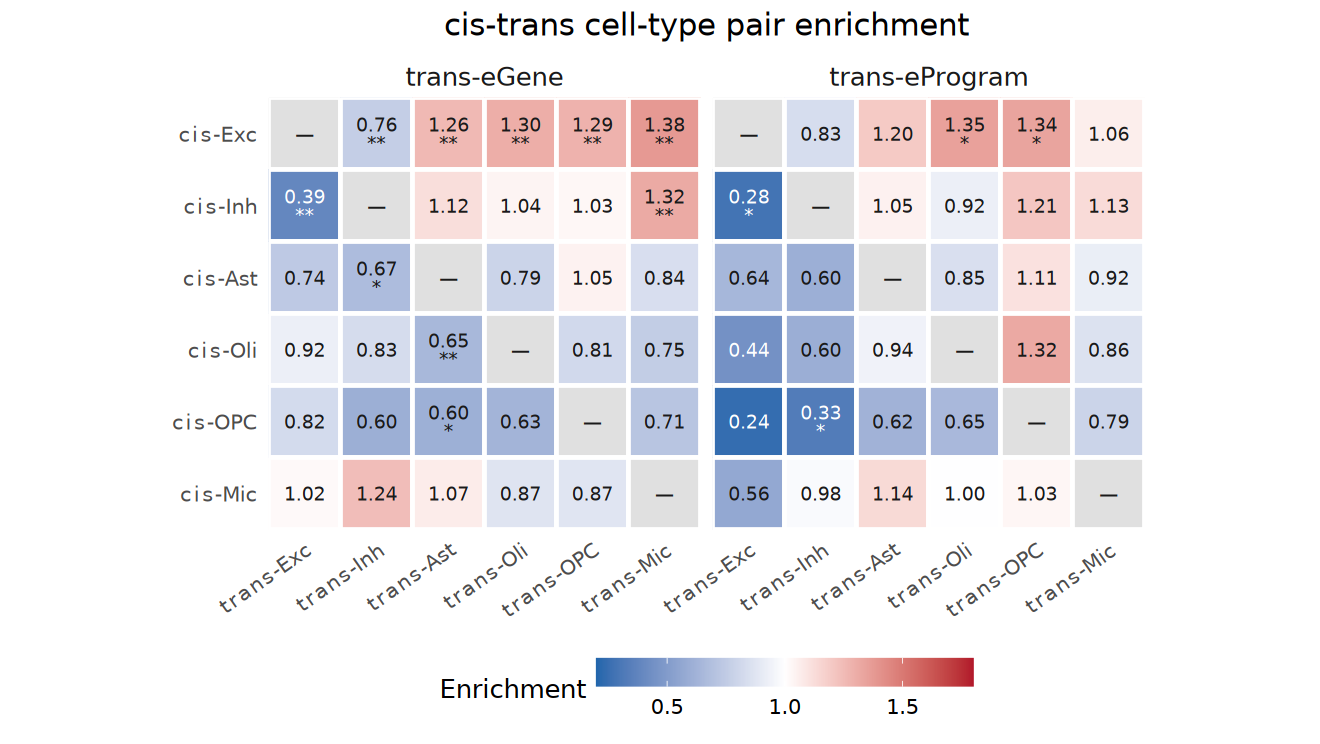

In [2]:
res$fill <- ifelse(res$diagonal, NA, res$enrichment)
res$label <- ifelse(res$diagonal, "\u2014",
                    paste0(sprintf("%.2f", res$enrichment), ifelse(res$sig == "", "", "\n"), res$sig))
dev_max <- ceiling(max(abs(res$fill - 1), na.rm = TRUE) * 10) / 10
res$txt <- ifelse(!is.na(res$fill) & abs(res$fill - 1) > 0.6 * dev_max, "white", "grey10")
res$cis_cell <- factor(res$cis_cell, levels = rev(levels(res$cis_cell)))

p <- ggplot(res, aes(x = trans_cell, y = cis_cell, fill = fill)) +
  geom_tile(colour = "white", linewidth = 1) +
  geom_text(aes(label = label, colour = txt), size = 3.8, lineheight = 0.85) +
  facet_wrap(~ trans_method, nrow = 1) +
  scale_colour_identity() +
  scale_fill_gradient2(low = "#2166AC", mid = "white", high = "#B2182B", midpoint = 1,
                       limits = c(max(0, 1 - dev_max), 1 + dev_max), oob = squish,
                       na.value = "grey88", name = "Enrichment") +
  scale_x_discrete(labels = function(x) parse(text = paste0("italic(trans)*'-", x, "'")),
                   expand = c(0, 0)) +
  scale_y_discrete(labels = function(x) parse(text = paste0("italic(cis)*'-", x, "'")),
                   expand = c(0, 0)) +
  coord_fixed() +
  labs(x = NULL, y = NULL, title = "cis-trans cell-type pair enrichment") +
  theme_minimal(base_size = 15) +
  theme(plot.title = element_text(hjust = 0.5), panel.grid = element_blank(),
        axis.text.x = element_text(angle = 35, hjust = 1), legend.position = "bottom",
        legend.key.width = grid::unit(1.6, "cm"), strip.text = element_text(size = 15))

options(repr.plot.width = 11, repr.plot.height = 6.2)
p